In [1]:
import sys

print("Python version:", sys.version)
print("Python location:", sys.executable)

Python version: 3.13.9 | packaged by Anaconda, Inc. | (main, Oct 21 2025, 19:09:58) [MSC v.1929 64 bit (AMD64)]
Python location: D:\AnacondaD\Anaconda\python.exe


In [2]:
%pip install pandas scikit-learn matplotlib gradio joblib

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [1]:
import pandas as pd
import sklearn
import matplotlib.pyplot as plt
import gradio as gr
import joblib

print("All packages imported successfully!")
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Gradio:", gr.__version__)

All packages imported successfully!
Pandas: 2.3.3
Scikit-learn: 1.7.2
Gradio: 6.17.3


In [2]:
import shutil
import subprocess

git_path = shutil.which("git")

if git_path:
    result = subprocess.run(
        ["git", "--version"],
        capture_output=True,
        text=True
    )
    print(result.stdout.strip())
else:
    print("Git was not found.")

git version 2.53.0.windows.1


In [3]:
from pathlib import Path
import subprocess

repo_url = "https://github.com/xahiru/PT22026.git"
repo_dir = Path.cwd() / "PT22026"

if repo_dir.exists():
    print("Folder already exists:", repo_dir)
else:
    subprocess.run(
        ["git", "clone", repo_url, str(repo_dir)],
        check=True
    )
    print("Repository downloaded:", repo_dir)

Repository downloaded: C:\Users\Mohammad\Desktop\Fith_Semister\Profesional Training\assignment\PT22026


In [4]:
project_dir = repo_dir / "ali081"

if not (repo_dir / ".git").exists():
    print("This is not a Git repository. Send me the previous output.")
elif not project_dir.is_dir():
    print("ali081 was not found. Send me the previous output.")
else:
    subprocess.run(
        ["git", "switch", "-c", "ali081-sentiment-analyzer"],
        cwd=repo_dir,
        check=True
    )

    print("Your project folder:", project_dir)
    print("Your working branch: ali081-sentiment-analyzer")

Your project folder: C:\Users\Mohammad\Desktop\Fith_Semister\Profesional Training\assignment\PT22026\ali081
Your working branch: ali081-sentiment-analyzer


In [1]:
from pathlib import Path
import subprocess

project_dir = Path.cwd()
repo_dir = project_dir.parent

print("Notebook working folder:", project_dir)

if project_dir.name != "ali081" or not (repo_dir / ".git").is_dir():
    print("Please open the notebook inside PT22026/ali081.")
else:
    # Create folders for our project.
    for folder in ["data", "models", "results"]:
        (project_dir / folder).mkdir(exist_ok=True)

    # Keep downloaded data and trained models out of Git.
    ignore_file = project_dir / ".gitignore"
    rules = [
        ".ipynb_checkpoints/",
        "__pycache__/",
        "/data/",
        "/models/",
        ".venv/",
    ]

    existing = (
        ignore_file.read_text(encoding="utf-8")
        if ignore_file.exists()
        else ""
    )

    missing = [rule for rule in rules if rule not in existing.splitlines()]

    if missing:
        with ignore_file.open("a", encoding="utf-8") as f:
            if existing and not existing.endswith("\n"):
                f.write("\n")
            f.write("\n".join(missing) + "\n")

    print("\nProject folders are ready!")

    result = subprocess.run(
        ["git", "status", "--short", "--", "ali081"],
        cwd=repo_dir,
        capture_output=True,
        text=True,
        check=True
    )
    print("\nGit status:")
    print(result.stdout)

Notebook working folder: C:\Users\Mohammad\Desktop\Fith_Semister\Profesional Training\assignment\PT22026\ali081

Project folders are ready!

Git status:
?? ali081/.gitignore
?? ali081/sentiment_analysis.ipynb



In [2]:
import subprocess

for setting in ["user.name", "user.email"]:
    result = subprocess.run(
        ["git", "config", "--get", setting],
        cwd=repo_dir,
        capture_output=True,
        text=True
    )
    print(f"{setting}: {result.stdout.strip() or 'NOT SET'}")

user.name: Alizada Mohammad
user.email: alizada.6600@.com


In [3]:
# Track only these two files in your assigned folder.
subprocess.run(
    [
        "git", "add",
        "ali081/.gitignore",
        "ali081/sentiment_analysis.ipynb"
    ],
    cwd=repo_dir,
    check=True
)

result = subprocess.run(
    [
        "git", "commit",
        "-m", "Set up sentiment analysis notebook and ignore local data",
        "--",
        "ali081/.gitignore",
        "ali081/sentiment_analysis.ipynb"
    ],
    cwd=repo_dir,
    capture_output=True,
    text=True
)

print(result.stdout)
print(result.stderr)

[ali081-sentiment-analyzer 93e5e2b] Set up sentiment analysis notebook and ignore local data
 2 files changed, 368 insertions(+)
 create mode 100644 ali081/.gitignore
 create mode 100644 ali081/sentiment_analysis.ipynb




In [4]:
from pathlib import Path
from urllib.request import urlopen
from io import BytesIO
import zipfile

project_dir = Path.cwd()

if project_dir.name != "ali081":
    raise RuntimeError("Open the notebook inside PT22026/ali081 first.")

data_dir = project_dir / "data"
data_dir.mkdir(exist_ok=True)

data_file = data_dir / "amazon_cells_labelled.txt"

url = (
    "https://archive.ics.uci.edu/static/public/331/"
    "sentiment%2Blabelled%2Bsentences.zip"
)

if data_file.exists():
    print("Dataset already downloaded:", data_file)
else:
    print("Downloading dataset...")

    with urlopen(url, timeout=60) as response:
        zip_bytes = response.read()

    with zipfile.ZipFile(BytesIO(zip_bytes)) as archive:
        matching_files = [
            name for name in archive.namelist()
            if name.endswith("/amazon_cells_labelled.txt")
            and not name.startswith("__MACOSX/")
        ]

        if len(matching_files) != 1:
            raise RuntimeError("Could not identify the Amazon dataset file.")

        data_file.write_bytes(archive.read(matching_files[0]))

    print("Download completed:", data_file)

Download completed: C:\Users\Mohammad\Desktop\Fith_Semister\Profesional Training\assignment\PT22026\ali081\data\amazon_cells_labelled.txt


In [5]:
import pandas as pd
import csv

df = pd.read_csv(
    data_file,
    sep="\t",
    header=None,
    names=["review", "label"],
    quoting=csv.QUOTE_NONE,
    encoding="utf-8"
)

print("Dataset shape:", df.shape)
print("\nNumber of reviews per label:")
print(df["label"].value_counts().sort_index())

print("\nMissing values:")
print(df.isna().sum())

print("\nFirst five reviews:")
display(df.head())

Dataset shape: (1000, 2)

Number of reviews per label:
label
0    500
1    500
Name: count, dtype: int64

Missing values:
review    0
label     0
dtype: int64

First five reviews:


,review,label
0,So there is no way for me to plug it in here i...,0
1,"Good case, Excellent value.",1
2,Great for the jawbone.,1
3,Tied to charger for conversations lasting more...,0
4,The mic is great.,1


In [6]:
# Keep the original df unchanged.
clean_df = df.dropna(subset=["review", "label"]).copy()

# Remove extra spaces while keeping words and punctuation.
clean_df["review"] = (
    clean_df["review"]
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

clean_df = clean_df[clean_df["review"] != ""].copy()

# Check that every label is valid.
assert clean_df["label"].isin([0, 1]).all(), "Unexpected label found."
clean_df["label"] = clean_df["label"].astype(int)

# Use lowercase text to detect repeated reviews.
clean_df["review_key"] = clean_df["review"].str.lower()

# Remove reviews that have conflicting labels.
label_counts = clean_df.groupby("review_key")["label"].nunique()
conflicting_keys = label_counts[label_counts > 1].index

conflict_mask = clean_df["review_key"].isin(conflicting_keys)
print("Rows with conflicting labels:", int(conflict_mask.sum()))

clean_df = clean_df[~conflict_mask].copy()

# Keep one copy of each remaining review.
duplicates = clean_df.duplicated(subset="review_key").sum()
print("Repeated rows removed:", int(duplicates))

clean_df = (
    clean_df.drop_duplicates(subset="review_key")
    .reset_index(drop=True)
)

print("Original reviews:", len(df))
print("Reviews after cleaning:", len(clean_df))
print("\nLabels after cleaning:")
print(clean_df["label"].value_counts().sort_index())

Rows with conflicting labels: 0
Repeated rows removed: 13
Original reviews: 1000
Reviews after cleaning: 987

Labels after cleaning:
label
0    496
1    491
Name: count, dtype: int64


In [7]:
from sklearn.model_selection import train_test_split

SEED = 42

# Reserve 30% for validation and testing.
train_df, remaining_df = train_test_split(
    clean_df,
    test_size=0.30,
    random_state=SEED,
    stratify=clean_df["label"]
)

# Divide that 30% into two equal parts.
val_df, test_df = train_test_split(
    remaining_df,
    test_size=0.50,
    random_state=SEED,
    stratify=remaining_df["label"]
)

# Verify that no duplicate review crosses between sets.
train_keys = set(train_df["review_key"])
val_keys = set(val_df["review_key"])
test_keys = set(test_df["review_key"])

assert train_keys.isdisjoint(val_keys)
assert train_keys.isdisjoint(test_keys)
assert val_keys.isdisjoint(test_keys)

summary = pd.DataFrame([
    {
        "Set": name,
        "Reviews": len(part),
        "Negative": int((part["label"] == 0).sum()),
        "Positive": int((part["label"] == 1).sum())
    }
    for name, part in [
        ("Training", train_df),
        ("Validation", val_df),
        ("Test", test_df)
    ]
])

display(summary)
print("Verified: no duplicate reviews shared between sets.")

# Save locally inside the ignored data folder.
for name, part in [
    ("train", train_df),
    ("validation", val_df),
    ("test", test_df)
]:
    part[["review", "label"]].to_csv(
        data_dir / f"{name}.csv",
        index=False
    )

print("All three datasets saved.")

,Set,Reviews,Negative,Positive
0,Training,690,347,343
1,Validation,148,74,74
2,Test,149,75,74


Verified: no duplicate reviews shared between sets.
All three datasets saved.


In [8]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression

models = {
    "Naive Bayes": Pipeline([
        ("tfidf", TfidfVectorizer(
            lowercase=True,
            ngram_range=(1, 2),
            stop_words=None
        )),
        ("classifier", MultinomialNB(alpha=1.0))
    ]),

    "Logistic Regression": Pipeline([
        ("tfidf", TfidfVectorizer(
            lowercase=True,
            ngram_range=(1, 2),
            stop_words=None
        )),
        ("classifier", LogisticRegression(
            max_iter=1000,
            random_state=42
        ))
    ])
}

print("Both model pipelines are ready.")

Both model pipelines are ready.


In [9]:
import pandas as pd
from time import perf_counter
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

X_train = train_df["review"]
y_train = train_df["label"]

X_val = val_df["review"]
y_val = val_df["label"]

rows = []

for name, model in models.items():
    start = perf_counter()

    # Learn only from training data.
    model.fit(X_train, y_train)

    training_seconds = perf_counter() - start

    train_predictions = model.predict(X_train)
    val_predictions = model.predict(X_val)

    rows.append({
        "Model": name,
        "Train accuracy": accuracy_score(
            y_train, train_predictions
        ),
        "Validation accuracy": accuracy_score(
            y_val, val_predictions
        ),
        "Macro precision": precision_score(
            y_val, val_predictions,
            average="macro", zero_division=0
        ),
        "Macro recall": recall_score(
            y_val, val_predictions,
            average="macro", zero_division=0
        ),
        "Macro F1": f1_score(
            y_val, val_predictions,
            average="macro", zero_division=0
        ),
        "Training seconds": training_seconds
    })

    print(f"{name}: training completed.")

comparison_df = (
    pd.DataFrame(rows)
    .sort_values(
        ["Macro F1", "Validation accuracy"],
        ascending=False
    )
    .reset_index(drop=True)
)

display(comparison_df.round(4))

results_dir = project_dir / "results"
results_dir.mkdir(exist_ok=True)

comparison_df.to_csv(
    results_dir / "validation_comparison.csv",
    index=False
)

print("Validation results saved.")

Naive Bayes: training completed.
Logistic Regression: training completed.


,Model,Train accuracy,Validation accuracy,Macro precision,Macro recall,Macro F1,Training seconds
0,Naive Bayes,0.9971,0.8243,0.8282,0.8243,0.8238,0.0737
1,Logistic Regression,0.9971,0.8176,0.8190,0.8176,0.8174,0.1839


Validation results saved.


In [10]:
from sklearn.base import clone
from sklearn.metrics import classification_report, accuracy_score, f1_score
import joblib
import json

# Select using validation results only.
best_name = comparison_df.iloc[0]["Model"]
final_model = clone(models[best_name])

# Combine training and validation data.
development_df = pd.concat(
    [train_df, val_df],
    ignore_index=True
)

final_model.fit(
    development_df["review"],
    development_df["label"]
)

# Evaluate on the untouched test set.
test_predictions = final_model.predict(test_df["review"])

test_accuracy = accuracy_score(
    test_df["label"], test_predictions
)
test_macro_f1 = f1_score(
    test_df["label"], test_predictions,
    average="macro", zero_division=0
)

print("Selected model:", best_name)
print("Final training reviews:", len(development_df))
print("Test reviews:", len(test_df))
print(f"Test accuracy: {test_accuracy:.2%}")
print(f"Test Macro F1: {test_macro_f1:.4f}")

report_text = classification_report(
    test_df["label"],
    test_predictions,
    labels=[0, 1],
    target_names=["Negative", "Positive"],
    digits=4,
    zero_division=0
)

print("\nClassification report:")
print(report_text)

# Save the entire pipeline: TF-IDF + classifier.
models_dir = project_dir / "models"
models_dir.mkdir(exist_ok=True)
results_dir = project_dir / "results"
results_dir.mkdir(exist_ok=True)

joblib.dump(final_model, models_dir / "sentiment_pipeline.joblib")

metrics = {
    "selected_model": best_name,
    "selection_metric": "validation macro F1",
    "final_training_reviews": len(development_df),
    "test_reviews": len(test_df),
    "test_accuracy": float(test_accuracy),
    "test_macro_f1": float(test_macro_f1)
}

(results_dir / "test_metrics.json").write_text(
    json.dumps(metrics, indent=2),
    encoding="utf-8"
)

(results_dir / "test_classification_report.txt").write_text(
    report_text,
    encoding="utf-8"
)

print("Model and test results saved.")

Selected model: Naive Bayes
Final training reviews: 838
Test reviews: 149
Test accuracy: 81.88%
Test Macro F1: 0.8172

Classification report:
              precision    recall  f1-score   support

    Negative     0.9000    0.7200    0.8000        75
    Positive     0.7640    0.9189    0.8344        74

    accuracy                         0.8188       149
   macro avg     0.8320    0.8195    0.8172       149
weighted avg     0.8325    0.8188    0.8171       149

Model and test results saved.


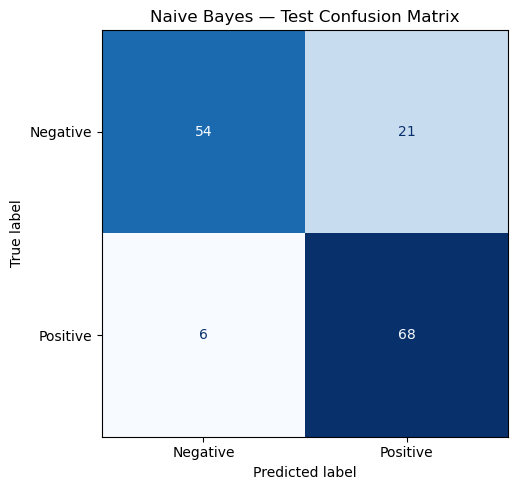

In [11]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(6, 5))

ConfusionMatrixDisplay.from_predictions(
    test_df["label"],
    test_predictions,
    labels=[0, 1],
    display_labels=["Negative", "Positive"],
    cmap="Blues",
    colorbar=False,
    ax=ax
)

ax.set_title(f"{best_name} — Test Confusion Matrix")
fig.tight_layout()

fig.savefig(
    results_dir / "test_confusion_matrix.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [12]:
# Match each test review with its prediction.
test_analysis = test_df[["review", "label"]].copy()
test_analysis["predicted_label"] = test_predictions

sentiment_names = {0: "Negative", 1: "Positive"}

test_analysis["Actual"] = (
    test_analysis["label"].map(sentiment_names)
)
test_analysis["Predicted"] = (
    test_analysis["predicted_label"].map(sentiment_names)
)

mistakes = test_analysis[
    test_analysis["label"] != test_analysis["predicted_label"]
].copy()

print("Total mistakes:", len(mistakes))

# Show examples of both kinds of mistake.
with pd.option_context("display.max_colwidth", None):
    print("\nNegative reviews predicted as positive:")
    display(
        mistakes[mistakes["label"] == 0]
        [["review", "Actual", "Predicted"]]
        .head(5)
    )

    print("\nPositive reviews predicted as negative:")
    display(
        mistakes[mistakes["label"] == 1]
        [["review", "Actual", "Predicted"]]
        .head(5)
    )

# Keep review-level data in the ignored data folder.
mistakes.to_csv(
    data_dir / "test_misclassifications.csv",
    index=False
)

print("Mistakes saved for analysis.")

Total mistakes: 27

Negative reviews predicted as positive:


,review,Actual,Predicted
574,Due to this happening on every call I was forced to stop using this headset.,Negative,Positive
917,Never got it!!!!!,Negative,Positive
669,Can't upload ringtones from a third party.,Negative,Positive
97,I found this product to be waaay too big.,Negative,Positive
542,Trying to make a call on these is an exercise in frustration.,Negative,Positive



Positive reviews predicted as negative:


,review,Actual,Predicted
519,I ended up sliding it on the edge of my pants or back pockets instead.,Positive,Negative
926,"I like the fact that it rests lightly against your ear, rather than inside.",Positive,Negative
889,The cutouts and buttons are placed perfectly.,Positive,Negative
964,":-)Oh, the charger seems to work fine.",Positive,Negative
540,"No shifting, no bubbling, no peeling, not even a scratch, NOTHING!I couldn't be more happier with my new one for the Droid.",Positive,Negative


Mistakes saved for analysis.
